<a href="https://colab.research.google.com/github/Yesid-Valencia/IntroduccionML---Especializacion-IA/blob/main/KMeansSegInmuebles.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Ejercicio ALG No Supervisado

Dataset original:
   Inmueble  area_m2  habitaciones  estrato  precio_arriendo
0        I1       45             1        3          1200000
1        I2       50             2        3          1400000
2        I3       60             2        4          1800000
3        I4       85             3        4          2600000
4        I5       90             3        5          3200000
5        I6      120             4        5          4500000
6        I7      130             4        6          5500000
7        I8       40             1        2           900000
8        I9       55             2        3          1500000
9       I10      100             3        5          3700000
10      I11      150             4        6          7000000
11      I12       35             1        2           800000

Dataset con clusters asignados:
   Inmueble  area_m2  habitaciones  estrato  precio_arriendo  cluster
0        I1       45             1        3          1200000        1
1        I2     

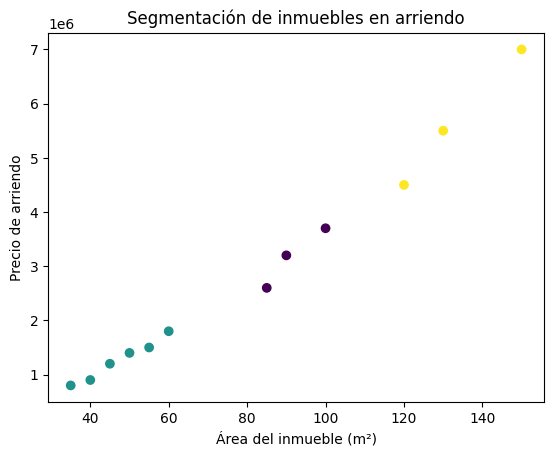


Resumen promedio por cluster:
            area_m2  habitaciones   estrato  precio_arriendo
cluster                                                     
0         91.666667           3.0  4.666667     3.166667e+06
1         47.500000           1.5  2.833333     1.266667e+06
2        133.333333           4.0  5.666667     5.666667e+06


In [1]:
# ============================================================
# LABORATORIO: Segmentación de inmuebles en arriendo
# Algoritmo no supervisado: K-Means
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# ============================================================
# 1. Crear dataset
# ============================================================

data = {
    "Inmueble": [
        "I1", "I2", "I3", "I4", "I5", "I6",
        "I7", "I8", "I9", "I10", "I11", "I12"
    ],
    "area_m2": [
        45, 50, 60, 85, 90, 120,
        130, 40, 55, 100, 150, 35
    ],
    "habitaciones": [
        1, 2, 2, 3, 3, 4,
        4, 1, 2, 3, 4, 1
    ],
    "estrato": [
        3, 3, 4, 4, 5, 5,
        6, 2, 3, 5, 6, 2
    ],
    "precio_arriendo": [
        1200000, 1400000, 1800000, 2600000,
        3200000, 4500000, 5500000, 900000,
        1500000, 3700000, 7000000, 800000
    ]
}

df = pd.DataFrame(data)

print("Dataset original:")
print(df)

# ============================================================
# 2. Seleccionar variables para clustering
# ============================================================

X = df[[
    "area_m2",
    "habitaciones",
    "estrato",
    "precio_arriendo"
]]

# ============================================================
# 3. Escalamiento de datos
# ============================================================

# K-Means usa distancias.
# Por eso es importante escalar los datos,
# ya que el precio tiene valores mucho más grandes que las otras variables.

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ============================================================
# 4. Aplicar K-Means
# ============================================================

# Vamos a crear 3 grupos de inmuebles:
# Cluster 0, Cluster 1 y Cluster 2

modelo = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

modelo.fit(X_scaled)

# Agregar el cluster al dataframe original
df["cluster"] = modelo.labels_

print("\nDataset con clusters asignados:")
print(df)

# ============================================================
# 5. Ver centroides
# ============================================================

centroides = modelo.cluster_centers_

print("\nCentroides escalados:")
print(centroides)

# Para interpretar mejor los centroides,
# los devolvemos a la escala original.

centroides_originales = scaler.inverse_transform(centroides)

df_centroides = pd.DataFrame(
    centroides_originales,
    columns=[
        "area_m2",
        "habitaciones",
        "estrato",
        "precio_arriendo"
    ]
)

print("\nCentroides en escala original:")
print(df_centroides)

# ============================================================
# 6. Visualización básica
# ============================================================

plt.scatter(
    df["area_m2"],
    df["precio_arriendo"],
    c=df["cluster"]
)

plt.xlabel("Área del inmueble (m²)")
plt.ylabel("Precio de arriendo")
plt.title("Segmentación de inmuebles en arriendo")
plt.show()

# ============================================================
# 7. Resumen por cluster
# ============================================================

resumen = df.groupby("cluster")[
    [
        "area_m2",
        "habitaciones",
        "estrato",
        "precio_arriendo"
    ]
].mean()

print("\nResumen promedio por cluster:")
print(resumen)

### Nueva implementación: Carga de datos desde Excel


¡Éxito! Se cargaron 1000 filas del archivo de Excel.


,Inmueble,Área m²,Habitaciones,Estrato,Precio arriendo,Baños,Antiguedad,Localidad,Tipo Inmueble
0,I1,69,2,2,1413951,2,11,Suba,Apto
1,I2,39,1,2,1006165,2,10,Chapinero,Casa
2,I3,142,5,5,8570904,1,8,Usaquén,ApartaEstudio
3,I4,62,3,4,3678698,1,12,Suba,Apto
4,I5,58,1,3,875729,1,12,Chapinero,Casa



Centroides en escala original:


,Área m²,Habitaciones,Estrato,Precio arriendo
0,49.658711,1.525060,2.501193,1.469202e+06
1,188.921053,3.952632,5.510526,6.392509e+06
2,121.058511,4.090426,5.553191,6.243451e+06
3,85.054187,2.487685,4.019704,3.100224e+06


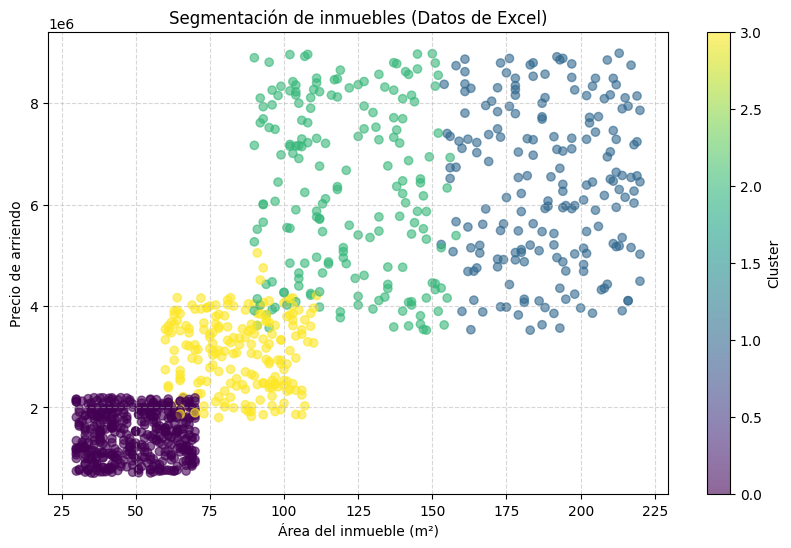


Resumen promedio por cluster:


,Área m²,Habitaciones,Estrato,Precio arriendo
cluster,,,,
0,49.658711,1.525060,2.501193,1.469202e+06
1,188.921053,3.952632,5.510526,6.392509e+06
2,121.058511,4.090426,5.553191,6.243451e+06
3,85.054187,2.487685,4.019704,3.100224e+06


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import os

# 1. Cargar el dataset desde Excel
archivo_excel = '/content/DATASET_INmuebles.xlsx'

if not os.path.exists(archivo_excel):
    print(f"⚠️ Por favor, sube el archivo '{archivo_excel}' a la barra lateral de Colab antes de continuar.")
else:
    # Leemos el archivo. pandas detectará automáticamente el motor openpyxl
    df = pd.read_excel(archivo_excel)
    print(f"¡Éxito! Se cargaron {len(df)} filas del archivo de Excel.")

    # Mostrar una muestra de los datos cargados
    display(df.head())

    # 2. Seleccionar variables para clustering
    # Asegúrate de que los nombres coincidan exactamente con las columnas de tu Excel
    columnas_features = ["Área m²", "Habitaciones", "Estrato", "Precio arriendo"]
    X = df[columnas_features]

    # 3. Escalamiento de datos
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # 4. Aplicar K-Means
    modelo = KMeans(
        n_clusters=4,
        random_state=42,
        n_init=10
    )
    modelo.fit(X_scaled)

    # Agregar el cluster al dataframe original
    df["cluster"] = modelo.labels_

    # 5. Ver centroides en escala original
    centroides = modelo.cluster_centers_
    centroides_originales = scaler.inverse_transform(centroides)
    df_centroides = pd.DataFrame(centroides_originales, columns=columnas_features)

    print("\nCentroides en escala original:")
    display(df_centroides)

    # 6. Visualización
    plt.figure(figsize=(10, 6))
    plt.scatter(
        df["Área m²"],
        df["Precio arriendo"],
        c=df["cluster"],
        cmap='viridis',
        alpha=0.6
    )
    plt.xlabel("Área del inmueble (m²)")
    plt.ylabel("Precio de arriendo")
    plt.title("Segmentación de inmuebles (Datos de Excel)")
    plt.colorbar(label='Cluster')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

    # 7. Resumen promedio por cluster
    resumen = df.groupby("cluster")[columnas_features].mean()
    print("\nResumen promedio por cluster:")
    display(resumen)